# Chương 4 — Đồ thị 01: Histogram phân bố tuổi

**Võ Minh Huy — 2311110117**

Vẽ từ bản after_Python trên đủ 299 hồ sơ; không cần nhãn DEATH_EVENT. Dùng cùng sáu khoảng rộng 10 năm như SQL. Các khoảng này chỉ phục vụ đồ thị, không thay mã nhóm tuổi A1–A4. Nếu kernel chưa có Matplotlib, ô đầu tiên sẽ cài thư viện này vào đúng môi trường Python đang chạy.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
tuoi = pd.to_numeric(du_lieu["age"], errors="raise")
if len(tuoi) != 299 or tuoi.isna().any() or not tuoi.between(40, 100, inclusive="left").all():
    raise ValueError("Kiểm tra tuổi: cần 299 giá trị trong [40,100).")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/01_histogram_tuoi"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"SoHoSo":[len(tuoi)], "Min":[tuoi.min()], "Max":[tuoi.max()],
    "Mean":[tuoi.mean()], "Median":[tuoi.median()], "DoRongKhoang":[10]}).round(2)

,SoHoSo,Min,Max,Mean,Median,DoRongKhoang
0,299,40.0,95.0,60.74,60.0,10


## 1. Thống kê và đối chiếu SQL

Các khoảng trái đóng, phải mở: tuổi 50 vào [50,60). Giá trị lớn nhất là 95 nên quy ước cận phải cuối của numpy.histogram không ảnh hưởng số đếm.

In [2]:
can = np.array([40, 50, 60, 70, 80, 90, 100])
so_luong, _ = np.histogram(tuoi.to_numpy(), bins=can)
tan_suat = pd.DataFrame({"STT":range(1, 7), "CanDuoi":can[:-1], "CanTren":can[1:],
    "KhoangTuoi":[f"[{a}, {b})" for a, b in zip(can[:-1], can[1:])],
    "SoHoSo":so_luong, "TyLePhanTram":(100*so_luong/len(tuoi)).round(2)})
sql = pd.read_csv(thu_muc_kq / "tan_suat_sql.csv")
cot_so_sanh = ["STT", "CanDuoi", "CanTren", "SoHoSo", "TyLePhanTram"]
if not np.allclose(tan_suat[cot_so_sanh], sql[cot_so_sanh], rtol=0, atol=1e-10):
    raise ValueError("Tần suất Python không khớp SQL.")
assert int(so_luong.sum()) == len(tuoi)
tan_suat.to_csv(thu_muc_kq / "tan_suat_python.csv", index=False, encoding="utf-8-sig")
tan_suat

,STT,CanDuoi,CanTren,KhoangTuoi,SoHoSo,TyLePhanTram
0,1,40,50,"[40, 50)",42,14.05
1,2,50,60,"[50, 60)",77,25.75
2,3,60,70,"[60, 70)",111,37.12
3,4,70,80,"[70, 80)",48,16.05
4,5,80,90,"[80, 90)",16,5.35
5,6,90,100,"[90, 100)",5,1.67


## 2. Vẽ histogram và lưu hình

Trục X là tuổi, trục Y là số hồ sơ. Các cột liền nhau vì đây là các khoảng liên tiếp của biến định lượng. Vẽ trực tiếp từ 299 giá trị tuổi; dùng bảng SQL để kiểm chứng số đếm.

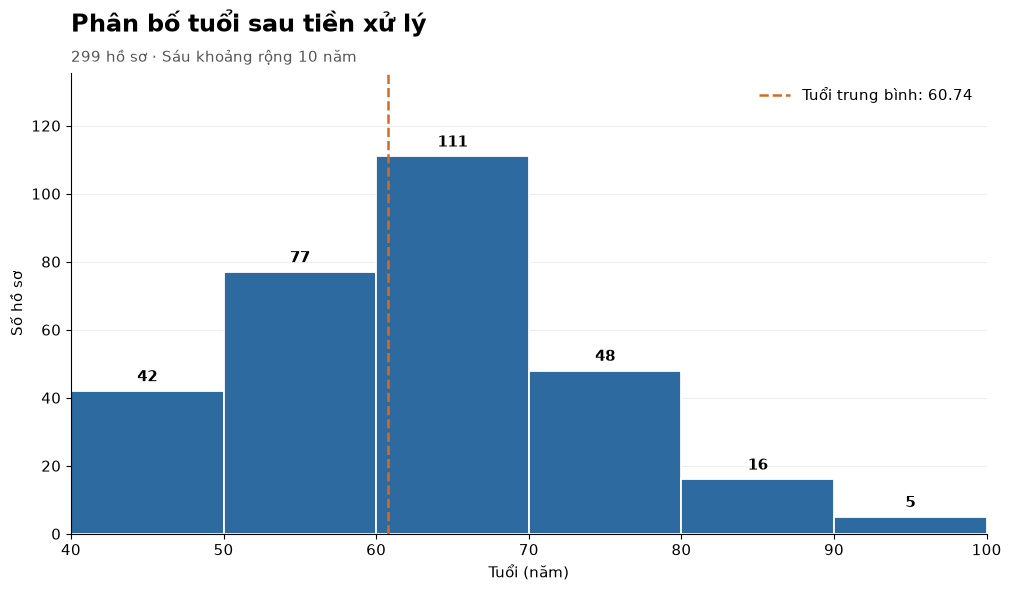

In [3]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(10, 5.8), layout="constrained")
n, edges, bars = ax.hist(tuoi.to_numpy(), bins=can, color="#2D6A9F",
    edgecolor="white", linewidth=1.3)
assert np.array_equal(n.astype(int), so_luong)
ax.set_title("Phân bố tuổi sau tiền xử lý", loc="left", fontsize=17, fontweight="bold", pad=30)
ax.text(0, 1.025, "299 hồ sơ · Sáu khoảng rộng 10 năm", transform=ax.transAxes, color="#555555")
ax.set_xlabel("Tuổi (năm)")
ax.set_ylabel("Số hồ sơ")
ax.set_xticks(can)
ax.set_xlim(40, 100)
ax.set_ylim(0, max(n)*1.22)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)
for count, left, right in zip(n, edges[:-1], edges[1:]):
    ax.text((left+right)/2, count+1.8, str(int(count)), ha="center", va="bottom", fontweight="bold")
ax.axvline(tuoi.mean(), color="#D46A24", linewidth=1.8, linestyle="--",
    label=f"Tuổi trung bình: {tuoi.mean():.2f}")
ax.legend(frameon=False, loc="upper right")
file_hinh = thu_muc_kq / "01_histogram_tuoi.png"
fig.savefig(file_hinh, dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

## 3. Nhận xét

- Khoảng [60,70) có 111 hồ sơ, chiếm 37,12%, cao nhất trong sáu khoảng.
- Từ 50 đến dưới 70 tuổi có 188 hồ sơ, tương ứng 62,88% dữ liệu.
- Tuổi nhỏ nhất 40, lớn nhất 95; mean khoảng 60,74 và median 60.
- Histogram mô tả dữ liệu sau xử lý, có cả tuổi đã điền bằng median nhóm. Không suy rộng phân bố này thành tỷ lệ mắc bệnh theo tuổi trong dân số.

In [4]:
pd.DataFrame({"TrangThai":["Đã lưu hình PNG 300 dpi và bảng tần suất; sáu khoảng khớp SQL."],
              "TongSoHoSo":[int(n.sum())], "SoKhoang":[len(n)]})

,TrangThai,TongSoHoSo,SoKhoang
0,Đã lưu hình PNG 300 dpi và bảng tần suất; sáu ...,299,6
